## I. Preamble

In [1]:
import csv
import time
import os
from datetime import datetime
from collections import deque
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

In [2]:
import sys
sys.path.append(r"C:\TUC\03 Scripts\Laborinstrumente\src") #Folder of the library
import Controller336

In [3]:
channel_ColdPlate="a"
channel_FreeLength="b"
channel_RadShield="c"
channel_2ndStage="d"

## Configuration

In [4]:
controller=Controller336.device(channel_ColdPlate="a",
                                channel_FreeLength="b",
                                channel_RadShield="c",
                                channel_2ndStage="d") #Only the channel connected to the instrument


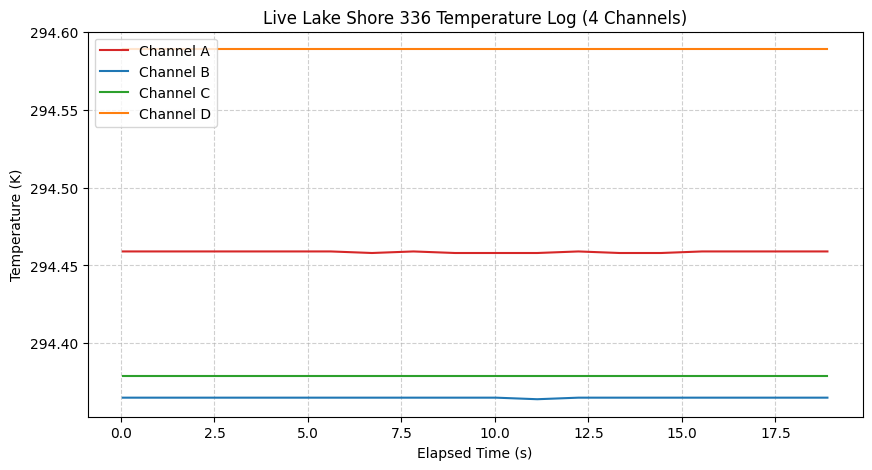


Logging stopped successfully.


In [ ]:
log_dir = r"C:\TUC\03 Scripts\Laborinstrumente\ARS_data_logs"
os.makedirs(log_dir, exist_ok=True)

start_time_str = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
CSV_FILENAME = os.path.join(log_dir, f"temperature_log_{start_time_str}.csv")
INTERVAL_SEC = 1.0       # Read/Plot every 1 second
DISPLAY_POINTS = 600     # Keep last 600 points on screen (10 minutes)

# Data buffers
time_buffer = deque(maxlen=DISPLAY_POINTS)
ch1_buffer = deque(maxlen=DISPLAY_POINTS)
ch2_buffer = deque(maxlen=DISPLAY_POINTS)
ch3_buffer = deque(maxlen=DISPLAY_POINTS)
ch4_buffer = deque(maxlen=DISPLAY_POINTS)

# 1. Initialize CSV File with Headers
with open(CSV_FILENAME, mode='a', newline='') as f:
    writer = csv.writer(f)
    if f.tell() == 0:  # Only write headers if file is empty
        writer.writerow(["Timestamp", "Elapsed_Sec", "Temp_ColdPlate", "Temp_FreeLength", "Temp_RadShield", "Temp_2ndStage"])

start_time = time.time()
fig, ax = plt.subplots(figsize=(10, 5))

print("Logging started... Interrupt kernel (Stop button) to finish.")

try:
    while True:
        # 2. Read temperature from controller
        try:
            t1, t2, t3, t4 = controller.getTemperature()
        except Exception as e:
            print(f"Read error: {e}")
            time.sleep(INTERVAL_SEC)
            continue

        now = datetime.now()
        elapsed = time.time() - start_time

        # 3. Write data to CSV on disk IMMEDIATELY
        with open(CSV_FILENAME, mode="a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([now.isoformat(), f"{elapsed:.2f}", t1, t2, t3, t4])
            f.flush()

        # 4. Update plot buffers
        time_buffer.append(elapsed)
        ch1_buffer.append(t1)
        ch2_buffer.append(t2)
        ch3_buffer.append(t3)
        ch4_buffer.append(t4)

        # 5. Redraw graph in Jupyter Output Area
        ax.clear()
        ax.plot(time_buffer, ch1_buffer, label="Channel A", color="tab:red", lw=1.5)
        ax.plot(time_buffer, ch2_buffer, label="Channel B", color="tab:blue", lw=1.5)
        ax.plot(time_buffer, ch3_buffer, label="Channel C", color="tab:green", lw=1.5)
        ax.plot(time_buffer, ch4_buffer, label="Channel D", color="tab:orange", lw=1.5)

        ax.set_title("Live Lake Shore 336 Temperature Log (4 Channels)", fontsize=12)
        ax.set_xlabel("Elapsed Time (s)", fontsize=10)
        ax.set_ylabel("Temperature (K)", fontsize=10)
        ax.grid(True, linestyle="--", alpha=0.6)
        ax.legend(loc="upper left")

        # Refresh cell display
        clear_output(wait=True)
        display(fig)

        # Pause until next interval
        time.sleep(INTERVAL_SEC)
 
except KeyboardInterrupt:
    print("\nLogging stopped successfully.")
finally:
    plt.close(fig)


In [12]:
## Command##

controller.getTemperature() #Read the temperature

(294.462, 294.368, 294.388, 294.578)

In [ ]:
controller.prepareHeaters()

In [ ]:
controller.startControlColdPlate(300)

In [ ]:
controller.startControlRadShield(300)

In [ ]:
controller.stopControl()